# Phase 3 — Exploratory Data Analysis (EDA)

## Objective

The objective of this phase is to perform a structured EDA on `merged_data` and understand fraud distribution, transaction behavior, missingness, identity coverage, cardinality, outliers, time behavior, correlations, and potential risks.

Only analysis is performed. No imputation, encoding, scaling, feature selection, model training, or deployment is performed.

## 1. EDA Objective and Scope

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
print("EDA scope: inspect and explain merged_data only.")
print("Transformations such as filling, encoding, scaling, and feature selection: NOT PERFORMED")

EDA scope: inspect and explain merged_data only.
Transformations such as filling, encoding, scaling, and feature selection: NOT PERFORMED


**Interpretation:** The notebook is intentionally descriptive. Any recommendations at the end are plans for the next phase, not implemented changes.

## 2. Load merged_data

In [2]:
from pathlib import Path

project = Path.cwd().parent
merged_path = project / "data" / "processed" / "merged_data.csv.gz"
merged_data = pd.read_csv(merged_path, compression="gzip", low_memory=False)
print("Loaded:", merged_path)
print("Shape:", merged_data.shape)

Loaded: C:\Users\HP\Desktop\fraud-detection-system\data\processed\merged_data.csv.gz
Shape: (590540, 434)


## 3. Dataset Overview

In [3]:
print("Rows:", len(merged_data))
print("Columns:", len(merged_data.columns))
print("Memory usage:", round(merged_data.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
print("Head:")
display(merged_data.head())
print("Data types:")
display(merged_data.dtypes.value_counts())
numeric_columns = merged_data.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_columns if c != "isFraud"]
categorical_columns = merged_data.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", len(numeric_columns))
print("Numerical features excluding target:", len(numeric_features))
print("Categorical columns:", len(categorical_columns))

Rows: 590540
Columns: 434


Memory usage: 1984.2 MB
Head:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


Data types:


float64    399
str         31
int64        4
Name: count, dtype: int64

Numerical columns: 403
Numerical features excluding target: 402
Categorical columns: 31


C:\Users\HP\AppData\Local\Temp\ipykernel_3780\551668631.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = merged_data.select_dtypes(include=["object", "category"]).columns.tolist()


**Interpretation:** The result should agree with Phase 2: 590,540 rows and 434 columns. The merged dataset remains wide, so later modeling will need memory-aware processing.

## 4. Target Distribution

In [4]:
target_counts = merged_data["isFraud"].value_counts().sort_index()
target_percent = merged_data["isFraud"].value_counts(normalize=True).sort_index() * 100
fraud_count = int(target_counts.get(1, 0))
legitimate_count = int(target_counts.get(0, 0))
print("Counts:")
display(target_counts)
print("Percentages:")
display(target_percent)
print("Total Transactions:", len(merged_data))
print("Legitimate:", legitimate_count)
print("Fraud:", fraud_count)
print("Imbalance Ratio (legitimate/fraud):", legitimate_count / fraud_count)

Counts:


isFraud
0    569877
1     20663
Name: count, dtype: int64

Percentages:


isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Total Transactions: 590540
Legitimate: 569877
Fraud: 20663
Imbalance Ratio (legitimate/fraud): 27.579586700866283


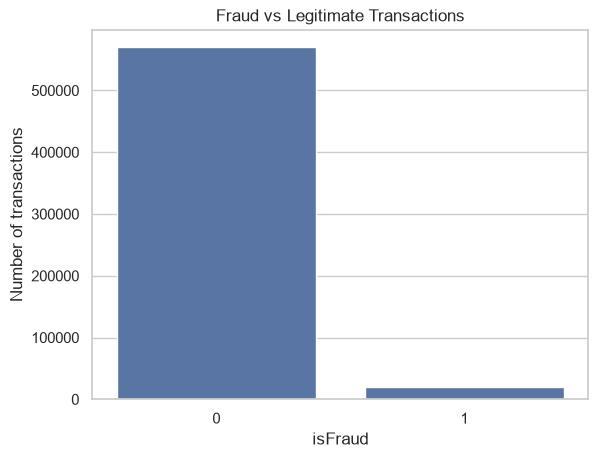

In [5]:
sns.countplot(data=merged_data, x="isFraud")
plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("isFraud")
plt.ylabel("Number of transactions")
plt.show()

**Interpretation:** Fraud is the minority class. Accuracy can be misleading in this setting; later model evaluation should emphasize precision, recall, F1, and PR-AUC.

## 5. Transaction Amount Analysis

In [6]:
amount_summary = merged_data["TransactionAmt"].describe()
display(amount_summary)
print("Mean:", merged_data["TransactionAmt"].mean())
print("Median:", merged_data["TransactionAmt"].median())
print("Standard deviation:", merged_data["TransactionAmt"].std())
print("Quantiles:")
display(merged_data["TransactionAmt"].quantile([0.01, 0.25, 0.50, 0.75, 0.90, 0.99, 0.999]))

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

Mean: 135.02717637247264
Median: 68.769
Standard deviation: 239.16252201373405
Quantiles:


0.010       9.24400
0.250      43.32100
0.500      68.76900
0.750     125.00000
0.900     275.29300
0.990    1104.00000
0.999    2769.80732
Name: TransactionAmt, dtype: float64

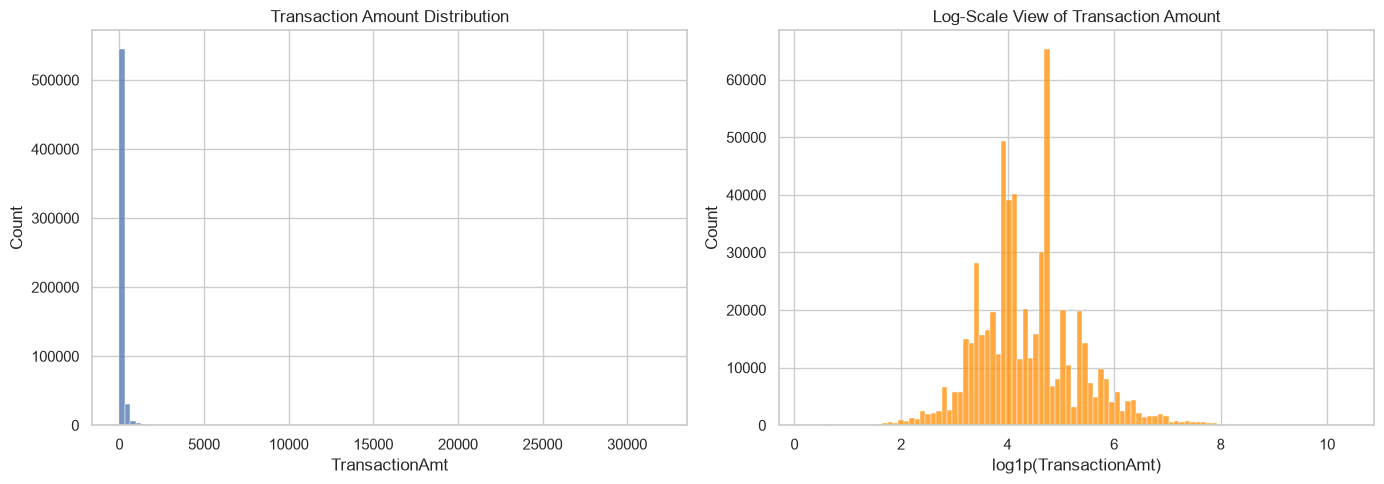

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(merged_data["TransactionAmt"], bins=100, ax=axes[0])
axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("TransactionAmt")
axes[0].set_ylabel("Count")
sns.histplot(np.log1p(merged_data["TransactionAmt"]), bins=100, ax=axes[1], color="darkorange")
axes[1].set_title("Log-Scale View of Transaction Amount")
axes[1].set_xlabel("log1p(TransactionAmt)")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

**Interpretation:** The second plot is only a visualization aid; no transformed feature is created or saved.

## 6. Transaction Amount by Fraud Class

In [8]:
amount_by_fraud = merged_data.groupby("isFraud")["TransactionAmt"].agg(["count", "mean", "median", "std", "min", "max"])
display(amount_by_fraud)
display(merged_data.groupby("isFraud")["TransactionAmt"].quantile([0.25, 0.75, 0.90, 0.99]).unstack())

,count,mean,median,std,min,max
isFraud,,,,,,
0,569877,134.511665,68.5,239.395078,0.251,31937.391
1,20663,149.244779,75.0,232.212163,0.292,5191.000


,0.25,0.75,0.90,0.99
isFraud,,,,
0,43.970,120.0,267.112,1104.0
1,35.044,161.0,335.000,994.0


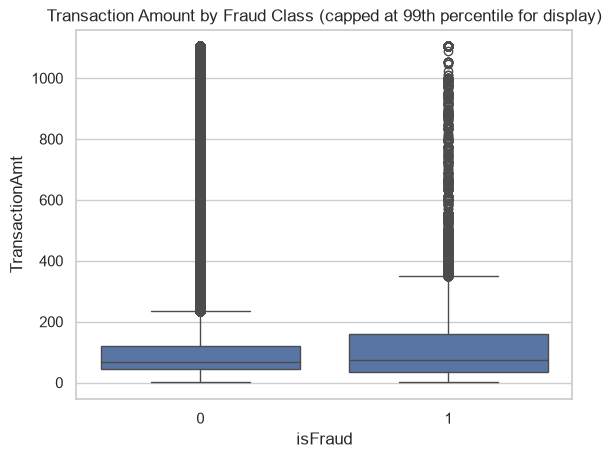

In [9]:
plot_data = merged_data[["isFraud", "TransactionAmt"]].copy()
plot_data["AmountForPlot"] = plot_data["TransactionAmt"].clip(upper=plot_data["TransactionAmt"].quantile(0.99))
sns.boxplot(data=plot_data, x="isFraud", y="AmountForPlot")
plt.title("Transaction Amount by Fraud Class (capped at 99th percentile for display)")
plt.xlabel("isFraud")
plt.ylabel("TransactionAmt")
plt.show()

**Interpretation:** Differences in group summaries or boxplots are exploratory associations. They do not by themselves prove that transaction amount is predictive or causal.

## 7. Numerical Feature Inventory and Summary

In [10]:
numeric_summary = merged_data[numeric_features].describe().T
numeric_summary["Missing %"] = merged_data[numeric_features].isna().mean() * 100
numeric_summary["Unique Values"] = merged_data[numeric_features].nunique(dropna=False)
print("Number of numerical features:", len(numeric_features))
print("Most missing numerical features:")
display(numeric_summary.sort_values("Missing %", ascending=False).head(15))
print("Numerical features with the largest ranges:")
numeric_summary["Range"] = numeric_summary["max"] - numeric_summary["min"]
display(numeric_summary.sort_values("Range", ascending=False).head(15))

Number of numerical features: 402
Most missing numerical features:


,count,mean,std,min,25%,50%,75%,max,Missing %,Unique Values
id_24,4747.0,12.800927,2.372447,11.0,11.0,11.0,15.0,26.0,99.196159,13
id_25,5132.0,329.608924,97.461089,100.0,321.0,321.0,371.0,548.0,99.130965,342
id_07,5155.0,13.285354,11.384207,-46.0,5.0,14.0,22.0,61.0,99.127070,85
id_08,5155.0,-38.600388,26.084899,-100.0,-48.0,-34.0,-23.0,0.0,99.127070,95
id_21,5159.0,368.269820,198.847038,100.0,252.0,252.0,486.5,854.0,99.126393,491
id_26,5163.0,149.070308,32.101995,100.0,119.0,149.0,169.0,216.0,99.125715,96
id_22,5169.0,16.002708,6.897665,10.0,14.0,14.0,14.0,44.0,99.124699,26
dist2,37627.0,231.855423,529.053494,0.0,7.0,37.0,206.0,11623.0,93.628374,1752
D7,38917.0,41.638950,99.743264,0.0,0.0,0.0,17.0,843.0,93.409930,598
id_18,45113.0,14.237337,1.561302,10.0,13.0,15.0,15.0,29.0,92.360721,19


Numerical features with the largest ranges:


,count,mean,std,min,25%,50%,75%,max,Missing %,Unique Values,Range
TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.0,3027057.75,7306527.5,1.124662e+07,1.581113e+07,0.000000,573349,1.572473e+07
id_02,140872.0,1.747166e+05,1.596518e+05,1.0,67992.00,125800.5,2.287490e+05,9.995950e+05,76.145223,115656,9.995940e+05
V160,81951.0,4.745318e+04,1.420761e+05,0.0,0.00,0.0,0.000000e+00,6.415114e+05,86.122701,9622,6.415114e+05
TransactionID,590540.0,3.282270e+06,1.704744e+05,2987000.0,3134634.75,3282269.5,3.429904e+06,3.577539e+06,0.000000,590540,5.905390e+05
V331,82351.0,7.217419e+02,6.217224e+03,0.0,0.00,0.0,0.000000e+00,1.600000e+05,86.054967,1759,1.600000e+05
V332,82351.0,1.375784e+03,1.116928e+04,0.0,0.00,0.0,2.500000e+01,1.600000e+05,86.054967,2454,1.600000e+05
V333,82351.0,1.014623e+03,7.955735e+03,0.0,0.00,0.0,0.000000e+00,1.600000e+05,86.054967,1972,1.600000e+05
V127,590226.0,3.366116e+02,4.238667e+03,0.0,0.00,0.0,1.079500e+02,1.600000e+05,0.053172,24415,1.600000e+05
V128,590226.0,2.040940e+02,3.010259e+03,0.0,0.00,0.0,0.000000e+00,1.600000e+05,0.053172,14508,1.600000e+05
V126,590226.0,1.299794e+02,2.346952e+03,0.0,0.00,0.0,0.000000e+00,1.600000e+05,0.053172,10300,1.600000e+05


**Interpretation:** The summary identifies features for focused inspection without producing hundreds of unreadable plots.

## 8. Selected Numerical Features vs Fraud

In [11]:
selected_numeric = [c for c in ["TransactionAmt", "TransactionDT", "card1", "card2", "card3", "card5", "addr1", "addr2"] if c in merged_data.columns]
selected_numeric_stats = merged_data.groupby("isFraud")[selected_numeric].agg(["mean", "median", "std"])
display(selected_numeric_stats)

TransactionAmt                    TransactionDT             \
                  mean median         std          mean     median   
isFraud                                                              
0           134.511665   68.5  239.395078  7.360791e+06  7271678.0   
1           149.244779   75.0  232.212163  7.690033e+06  7575230.0   

                             card1                           card2  ...  \
                  std         mean  median         std        mean  ...   
isFraud                                                             ...   
0        4.623930e+06  9911.464381  9711.0  4905.67237  362.453981  ...   
1        4.416551e+06  9547.654164  9633.0  4762.05138  365.370850  ...   

             card3       card5                         addr1         \
               std        mean median        std        mean median   
isFraud                                                               
0        10.904432  199.542212  226.0  41.046975  290.643341  299.0   
1        17.495775  191.994328  224.0  45.779886  294.317134  299.0   

                         addr2                   
                std       mean median       std  
isFraud                                          
0        101.692564  86.813620   87.0  2.607742  
1        103.584955  86.286024   87.0  4.936238  

[2 rows x 24 columns]

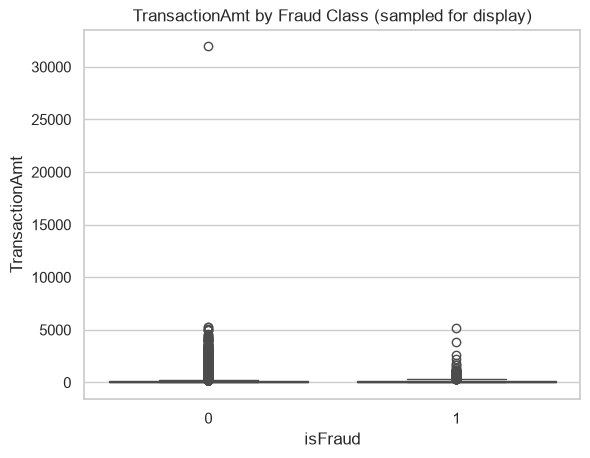

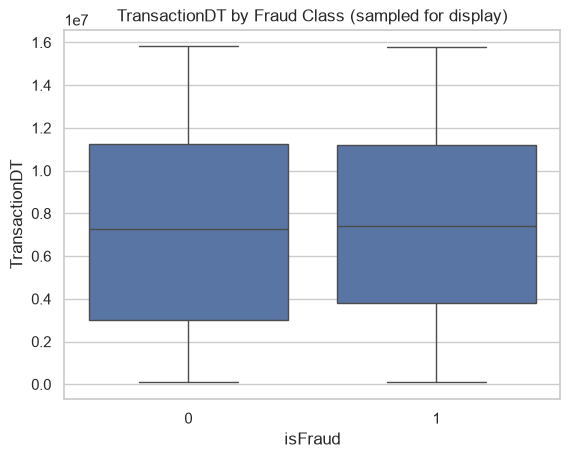

In [12]:
for feature in [c for c in ["TransactionAmt", "TransactionDT"] if c in merged_data.columns]:
    sample = merged_data[["isFraud", feature]].dropna()
    sample = sample.sample(n=min(100000, len(sample)), random_state=42)
    sns.boxplot(data=sample, x="isFraud", y=feature)
    plt.title(f"{feature} by Fraud Class (sampled for display)")
    plt.xlabel("isFraud")
    plt.ylabel(feature)
    plt.show()

## 9. Categorical Feature Inventory and Cardinality

In [13]:
print("Number of categorical features:", len(categorical_columns))
cardinality = pd.DataFrame({
    "Feature": categorical_columns,
    "Unique Values": [merged_data[c].nunique(dropna=False) for c in categorical_columns],
    "Missing %": [merged_data[c].isna().mean() * 100 for c in categorical_columns]
})
cardinality["Cardinality"] = pd.cut(cardinality["Unique Values"], bins=[-1, 10, 100, np.inf], labels=["Low", "Medium", "High"])
display(cardinality.sort_values("Unique Values", ascending=False))

Number of categorical features: 31


,Feature,Unique Values,Missing %,Cardinality
30,DeviceInfo,1787,79.905510,High
23,id_33,261,87.589494,High
22,id_31,131,76.245132,High
21,id_30,76,86.865411,Medium
4,R_emaildomain,61,76.751617,Medium
3,P_emaildomain,60,15.994852,Medium
0,ProductCD,5,0.000000,Low
2,card6,5,0.266028,Low
1,card4,5,0.267044,Low
24,id_34,5,86.824771,Low


**Interpretation:** Cardinality is descriptive here. High-cardinality fields may need a careful encoding strategy later; no encoding is performed now.

## 10. Selected Categorical Features vs Fraud

In [14]:
for feature in [c for c in ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain"] if c in merged_data.columns]:
    rates = merged_data.groupby(feature, dropna=False)["isFraud"].agg(["count", "mean"])
    rates["Fraud Rate %"] = rates["mean"] * 100
    print("\nFeature:", feature)
    display(rates.sort_values("count", ascending=False).head(15))


Feature: ProductCD


,count,mean,Fraud Rate %
ProductCD,,,
W,439670,0.020399,2.039939
C,68519,0.116873,11.687269
R,37699,0.037826,3.782594
H,33024,0.047662,4.766231
S,11628,0.058996,5.899553



Feature: card4


,count,mean,Fraud Rate %
card4,,,
visa,384767,0.034756,3.475610
mastercard,189217,0.034331,3.433095
american express,8328,0.028698,2.869837
discover,6651,0.077282,7.728161
NaN,1577,0.025999,2.599873



Feature: card6


,count,mean,Fraud Rate %
card6,,,
debit,439938,0.024263,2.426251
credit,148986,0.066785,6.678480
NaN,1571,0.024825,2.482495
debit or credit,30,0.000000,0.000000
charge card,15,0.000000,0.000000



Feature: P_emaildomain


,count,mean,Fraud Rate %
P_emaildomain,,,
gmail.com,228355,0.043542,4.354185
yahoo.com,100934,0.022757,2.275745
NaN,94456,0.029538,2.953756
hotmail.com,45250,0.052950,5.295028
anonymous.com,36998,0.023217,2.321747
aol.com,28289,0.021811,2.181060
comcast.net,7888,0.031187,3.118661
icloud.com,6267,0.031434,3.143450
outlook.com,5096,0.094584,9.458399



Feature: R_emaildomain


,count,mean,Fraud Rate %
R_emaildomain,,,
NaN,453249,0.020819,2.081858
gmail.com,57147,0.119184,11.918386
hotmail.com,27509,0.077793,7.779272
anonymous.com,20529,0.029130,2.912952
yahoo.com,11842,0.051512,5.151157
aol.com,3701,0.034855,3.485544
outlook.com,2507,0.165138,16.513761
comcast.net,1812,0.011589,1.158940
yahoo.com.mx,1508,0.010610,1.061008


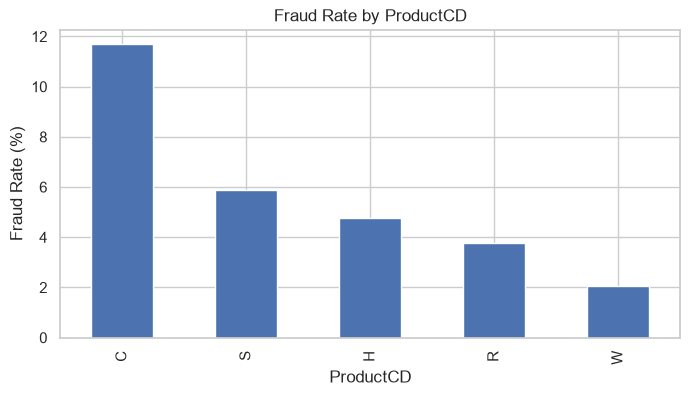

In [15]:
if "ProductCD" in merged_data.columns:
    product_rate = merged_data.groupby("ProductCD", dropna=False)["isFraud"].mean().mul(100).sort_values(ascending=False)
    product_rate.plot(kind="bar", figsize=(8, 4), title="Fraud Rate by ProductCD")
    plt.xlabel("ProductCD")
    plt.ylabel("Fraud Rate (%)")
    plt.show()

**Interpretation:** Category fraud-rate differences are exploratory and may reflect cohort or data-collection effects. They are not causal conclusions.

## 11. Missing Value Analysis

In [16]:
missing_count = merged_data.isnull().sum()
missing_percent = merged_data.isnull().mean() * 100
missing_table = pd.DataFrame({"Feature": merged_data.columns, "Missing Count": missing_count.values, "Missing %": missing_percent.values})
print("Overall missing cells:", int(missing_count.sum()))
print("Features with any missingness:", int((missing_count > 0).sum()))
display(missing_table.sort_values("Missing %", ascending=False).head(25))

Overall missing cells: 115523073
Features with any missingness: 414


,Feature,Missing Count,Missing %
417,id_24,585793,99.196159
418,id_25,585408,99.130965
400,id_07,585385,99.127070
401,id_08,585385,99.127070
414,id_21,585381,99.126393
419,id_26,585377,99.125715
420,id_27,585371,99.124699
416,id_23,585371,99.124699
415,id_22,585371,99.124699
14,dist2,552913,93.628374


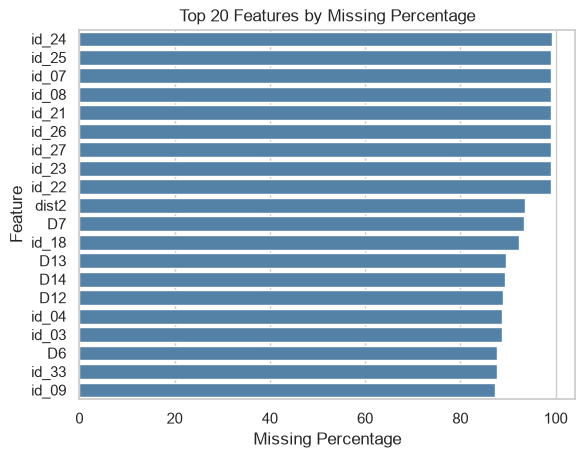

In [17]:
top_missing = missing_table.sort_values("Missing %", ascending=False).head(20)
sns.barplot(data=top_missing, y="Feature", x="Missing %", color="steelblue")
plt.title("Top 20 Features by Missing Percentage")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")
plt.show()

**Interpretation:** Missingness is a central characteristic of the integrated dataset. Missing values are not filled, and features are not removed in EDA.

## 12. Missingness vs Fraud and Identity Availability

In [18]:
missingness_results = []
for feature in [c for c in ["TransactionAmt", "ProductCD", "card2", "P_emaildomain", "DeviceType", "id_01", "id_02", "id_33"] if c in merged_data.columns]:
    rates = merged_data.groupby(merged_data[feature].isna())["isFraud"].agg(["count", "mean"])
    rates["Fraud Rate %"] = rates["mean"] * 100
    rates["Feature"] = feature
    rates["Status"] = rates.index.map({True: "Missing", False: "Present"})
    missingness_results.append(rates.reset_index(drop=True))
missingness_vs_fraud = pd.concat(missingness_results, ignore_index=True)
display(missingness_vs_fraud[["Feature", "Status", "count", "Fraud Rate %"]])

,Feature,Status,count,Fraud Rate %
0,TransactionAmt,Present,590540,3.499001
1,ProductCD,Present,590540,3.499001
2,card2,Present,581607,3.480013
3,card2,Missing,8933,4.735251
4,P_emaildomain,Present,496084,3.602817
5,P_emaildomain,Missing,94456,2.953756
6,DeviceType,Present,140810,7.961792
7,DeviceType,Missing,449730,2.101705
8,id_01,Present,144233,7.847025
9,id_01,Missing,446307,2.093850


In [19]:
identity_feature_columns = [c for c in ["DeviceType", "id_01", "id_02", "id_33"] if c in merged_data.columns]
identity_available = merged_data[identity_feature_columns].notna().any(axis=1)
identity_fraud = merged_data.assign(identity_available=identity_available).groupby("identity_available")["isFraud"].agg(["count", "sum", "mean"])
identity_fraud["Fraud Rate %"] = identity_fraud["mean"] * 100
display(identity_fraud)
print("Identity availability rule: at least one of the selected identity/device fields is non-missing.")

C:\Users\HP\AppData\Local\Temp\ipykernel_3780\317127654.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  identity_fraud = merged_data.assign(identity_available=identity_available).groupby("identity_available")["isFraud"].agg(["count", "sum", "mean"])


,count,sum,mean,Fraud Rate %
identity_available,,,,
False,446307,9345,0.020939,2.093850
True,144233,11318,0.078470,7.847025


Identity availability rule: at least one of the selected identity/device fields is non-missing.


**Interpretation:** Missingness may carry predictive information. The identity availability rule is explicit and based on any populated identity/device field, rather than an arbitrary single column. This is an association, not causation.

## 13. Identity Information Analysis

Transactions with Identity: 144233
Transactions without Identity: 446307
Identity Coverage %: 24.42391709283029
Fraud Rate with Identity %: 7.847025299342036
Fraud Rate without Identity %: 2.093850197285725


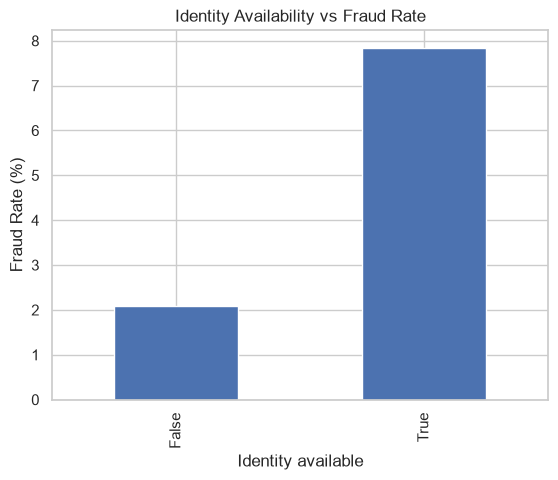

In [20]:
print("Transactions with Identity:", int(identity_available.sum()))
print("Transactions without Identity:", int((~identity_available).sum()))
print("Identity Coverage %:", identity_available.mean() * 100)
print("Fraud Rate with Identity %:", merged_data.loc[identity_available, "isFraud"].mean() * 100)
print("Fraud Rate without Identity %:", merged_data.loc[~identity_available, "isFraud"].mean() * 100)
identity_fraud["Fraud Rate %"].plot(kind="bar", title="Identity Availability vs Fraud Rate")
plt.xlabel("Identity available")
plt.ylabel("Fraud Rate (%)")
plt.show()

## 14. Outlier Analysis

In [21]:
outlier_rows = []
for feature in [c for c in ["TransactionAmt", "TransactionDT", "card1", "card2", "addr1", "addr2"] if c in merged_data.columns]:
    values = merged_data[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({"Feature": feature, "Q1": q1, "Q3": q3, "IQR": iqr, "Lower Bound": lower, "Upper Bound": upper, "Potential Outliers": count})
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers
0,TransactionAmt,43.321,125.0,81.679,-7.919750e+01,2.475185e+02,66482
1,TransactionDT,3027057.750,11246620.0,8219562.250,-9.302286e+06,2.357596e+07,0
2,card1,6019.000,14184.0,8165.000,-6.228500e+03,2.643150e+04,0
3,card2,214.000,512.0,298.000,-2.330000e+02,9.590000e+02,0
4,addr1,204.000,330.0,126.000,1.500000e+01,5.190000e+02,369
5,addr2,87.000,87.0,0.000,8.700000e+01,8.700000e+01,4353


**Interpretation:** IQR flags are screening signals only. Extreme financial transactions may be legitimate or useful for fraud detection, so no outliers are removed.

## 15. Time-related Analysis

TransactionDT exists.
Range: 86400 to 15811131


count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64

,count,mean,Fraud Rate %
TransactionDT,,,
"(86399.999, 1361004.4]",59054,0.027619,2.761879
"(1361004.4, 2310159.6]",59054,0.020236,2.023572
"(2310159.6, 3864163.9]",59054,0.037254,3.725404
"(3864163.9, 5592303.6]",59054,0.042876,4.287601
"(5592303.6, 7306527.5]",59054,0.039557,3.955702
"(7306527.5, 8745782.4]",59054,0.035459,3.545907
"(8745782.4, 10437998.1]",59054,0.043181,4.318082
"(10437998.1, 12192853.6]",59054,0.034900,3.490026
"(12192853.6, 13990907.7]",59054,0.031344,3.134419


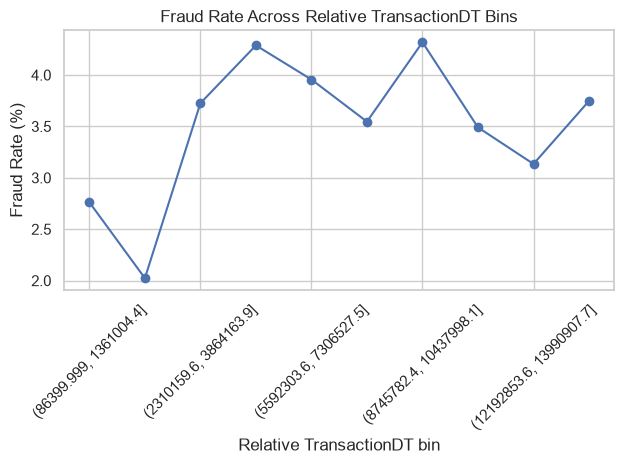

In [22]:
if "TransactionDT" in merged_data.columns:
    print("TransactionDT exists.")
    print("Range:", merged_data["TransactionDT"].min(), "to", merged_data["TransactionDT"].max())
    display(merged_data["TransactionDT"].describe())
    time_bins = pd.qcut(merged_data["TransactionDT"], q=10, duplicates="drop")
    time_fraud = merged_data.groupby(time_bins, observed=False)["isFraud"].agg(["count", "mean"])
    time_fraud["Fraud Rate %"] = time_fraud["mean"] * 100
    display(time_fraud)
    time_fraud["Fraud Rate %"].plot(kind="line", marker="o", title="Fraud Rate Across Relative TransactionDT Bins")
    plt.xlabel("Relative TransactionDT bin")
    plt.ylabel("Fraud Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No TransactionDT field is available; time analysis is not applicable.")

**Interpretation:** `TransactionDT` is treated as a relative time offset, not converted into artificial calendar timestamps. Quantile bins show relative patterns only.

## 16. Correlation Analysis

In [23]:
corr_sample = merged_data[["isFraud"] + numeric_features].sample(n=min(100000, len(merged_data)), random_state=42)
correlation = corr_sample.corr()
print("Strongest absolute correlations among numerical features (sample):")
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
pairs["Absolute Correlation"] = pairs["Correlation"].abs()
display(pairs.sort_values("Absolute Correlation", ascending=False).head(20))
print("Strongest exploratory numerical relationships with isFraud:")
target_correlations = correlation["isFraud"].drop("isFraud").sort_values(key=abs, ascending=False)
display(target_correlations.head(20).to_frame("Correlation with isFraud"))

Strongest absolute correlations among numerical features (sample):


,Feature 1,Feature 2,Correlation,Absolute Correlation
11724,D4,D12,1.000000,1.000000
55575,V97,V324,0.999963,0.999963
55171,V96,V323,0.999962,0.999962
54767,V95,V322,0.999954,0.999954
128919,V279,V322,0.999777,0.999777
129324,V280,V324,0.999764,0.999764
57185,V101,V322,0.999713,0.999713
54546,V95,V101,0.999613,0.999613
128890,V279,V293,0.999598,0.999598
134561,V293,V322,0.999563,0.999563


Strongest exploratory numerical relationships with isFraud:


,Correlation with isFraud
V257,0.365644
V246,0.346830
V244,0.344396
V242,0.341745
V201,0.312907
V200,0.300456
V258,0.296730
V189,0.295821
V158,0.294606
V156,0.289826


**Interpretation:** Correlation can reveal redundancy or exploratory signals, but it does not prove predictive usefulness, causation, or suitability for feature selection.

## 17. Potential Data Leakage Analysis

In [24]:
suspicious_features = [c for c in merged_data.columns if c.lower() in ["isfraud", "transactionid"] or "id" in c.lower() or "timestamp" in c.lower() or "time" in c.lower()]
print("Features requiring leakage review:")
print(suspicious_features)
print("\nReview notes:")
print("- isFraud is the target and must not be used as an input feature.")
print("- TransactionID is a direct identifier and should not automatically be treated as predictive.")
print("- TransactionDT must be available at prediction time and interpreted as a relative offset.")
print("- Identity/device fields require confirmation that they are available at prediction time.")

Features requiring leakage review:
['TransactionID', 'isFraud', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38']

Review notes:
- isFraud is the target and must not be used as an input feature.
- TransactionID is a direct identifier and should not automatically be treated as predictive.
- TransactionDT must be available at prediction time and interpreted as a relative offset.
- Identity/device fields require confirmation that they are available at prediction time.


**Interpretation:** These are review flags, not automatic removals. Leakage decisions belong to the later preprocessing/modeling design after understanding the prediction-time scenario.

## 18. Important EDA Findings and Recommendations

In [25]:
print("Key findings:")
print("1. The dataset remains highly imbalanced, so accuracy should not be the primary metric later.")
print("2. Missingness is extensive and identity coverage is incomplete; missingness may itself be informative.")
print("3. TransactionAmt has a wide distribution and potential extreme values; no outliers should be removed automatically.")
print("4. Categorical cardinality varies; high-cardinality fields need a deliberate later encoding strategy.")
print("5. TransactionDT is a relative time field and should not be converted to artificial dates without semantics.")
print("6. ID-like and post-transaction-like fields require leakage review before modeling.")
print("\nRecommendations for Phase 4:")
print("- Fit missing-value handling on training data only.")
print("- Compare simple categorical encodings appropriate to cardinality.")
print("- Keep a representative validation/test distribution.")
print("- Investigate, rather than automatically remove, outliers and suspicious identifiers.")
print("- Use a memory-aware preprocessing pipeline.")

Key findings:
1. The dataset remains highly imbalanced, so accuracy should not be the primary metric later.
2. Missingness is extensive and identity coverage is incomplete; missingness may itself be informative.
3. TransactionAmt has a wide distribution and potential extreme values; no outliers should be removed automatically.
4. Categorical cardinality varies; high-cardinality fields need a deliberate later encoding strategy.
5. TransactionDT is a relative time field and should not be converted to artificial dates without semantics.
6. ID-like and post-transaction-like fields require leakage review before modeling.

Recommendations for Phase 4:
- Fit missing-value handling on training data only.
- Compare simple categorical encodings appropriate to cardinality.
- Keep a representative validation/test distribution.
- Investigate, rather than automatically remove, outliers and suspicious identifiers.
- Use a memory-aware preprocessing pipeline.


## 19. Phase 3 — Final EDA Report

In [26]:
print("PHASE 3 — FINAL EDA REPORT")
print("=" * 40)
print("1. Dataset Overview")
print("Rows:", len(merged_data))
print("Columns:", len(merged_data.columns))
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_columns))
print("\n2. Target")
print("Fraud Count:", fraud_count)
print("Legitimate Count:", legitimate_count)
print("Fraud %:", target_percent.get(1, 0))
print("Imbalance Ratio:", legitimate_count / fraud_count)
print("\n3. Missing Values")
print("Overall Missing Cells:", int(missing_count.sum()))
print("Most Missing Features:", missing_table.sort_values("Missing %", ascending=False).head(10)["Feature"].tolist())
print("Important Pattern: identity fields are missing for transactions without identity records.")
print("\n4. Identity")
print("Identity Coverage %:", identity_available.mean() * 100)
print("Fraud Rate With Identity %:", merged_data.loc[identity_available, "isFraud"].mean() * 100)
print("Fraud Rate Without Identity %:", merged_data.loc[~identity_available, "isFraud"].mean() * 100)
print("\n5. Numerical Features")
print("TransactionAmt mean/median:", merged_data["TransactionAmt"].mean(), "/", merged_data["TransactionAmt"].median())
print("\n6. Categorical Features")
print("Highest-cardinality categorical features:")
display(cardinality.sort_values("Unique Values", ascending=False).head(10))
print("\n7. Cardinality")
print("High-cardinality categorical features:", cardinality.loc[cardinality["Cardinality"] == "High", "Feature"].tolist())
print("\n8. Outliers")
display(outlier_table[["Feature", "Potential Outliers"]])
print("No outliers removed.")
print("\n9. Time Patterns")
print("TransactionDT available:", "TransactionDT" in merged_data.columns)
print("\n10. Correlation")
display(pairs.sort_values("Absolute Correlation", ascending=False).head(5))
print("\n11. Potential Leakage")
print("Review TransactionID, isFraud, TransactionDT, and identity/device fields before modeling.")
print("\n12. Key Findings")
print("Imbalance, missingness, partial identity coverage, high-cardinality fields, wide distributions, and leakage review are the main findings.")
print("\n13. Preprocessing Recommendations")
print("Use train-only missing-value handling and encoding decisions; investigate outliers and identifiers before modeling.")
print("\nDECISION: Phase 3 EDA is complete. Do not start 04_preprocessing.ipynb until explicit approval.")

PHASE 3 — FINAL EDA REPORT
1. Dataset Overview
Rows: 590540
Columns: 434
Numerical Features: 402
Categorical Features: 31

2. Target
Fraud Count: 20663
Legitimate Count: 569877
Fraud %: 3.4990009144173126
Imbalance Ratio: 27.579586700866283

3. Missing Values
Overall Missing Cells: 115523073
Most Missing Features: ['id_24', 'id_25', 'id_07', 'id_08', 'id_21', 'id_26', 'id_27', 'id_23', 'id_22', 'dist2']
Important Pattern: identity fields are missing for transactions without identity records.

4. Identity
Identity Coverage %: 24.42391709283029
Fraud Rate With Identity %: 7.847025299342036
Fraud Rate Without Identity %: 2.093850197285725

5. Numerical Features


TransactionAmt mean/median: 135.02717637247264 / 68.769

6. Categorical Features
Highest-cardinality categorical features:


,Feature,Unique Values,Missing %,Cardinality
30,DeviceInfo,1787,79.905510,High
23,id_33,261,87.589494,High
22,id_31,131,76.245132,High
21,id_30,76,86.865411,Medium
4,R_emaildomain,61,76.751617,Medium
3,P_emaildomain,60,15.994852,Medium
0,ProductCD,5,0.000000,Low
2,card6,5,0.266028,Low
1,card4,5,0.267044,Low
24,id_34,5,86.824771,Low



7. Cardinality
High-cardinality categorical features: ['id_31', 'id_33', 'DeviceInfo']

8. Outliers


,Feature,Potential Outliers
0,TransactionAmt,66482
1,TransactionDT,0
2,card1,0
3,card2,0
4,addr1,369
5,addr2,4353


No outliers removed.

9. Time Patterns
TransactionDT available: True

10. Correlation


,Feature 1,Feature 2,Correlation,Absolute Correlation
11724,D4,D12,1.000000,1.000000
55575,V97,V324,0.999963,0.999963
55171,V96,V323,0.999962,0.999962
54767,V95,V322,0.999954,0.999954
128919,V279,V322,0.999777,0.999777



11. Potential Leakage
Review TransactionID, isFraud, TransactionDT, and identity/device fields before modeling.

12. Key Findings
Imbalance, missingness, partial identity coverage, high-cardinality fields, wide distributions, and leakage review are the main findings.

13. Preprocessing Recommendations
Use train-only missing-value handling and encoding decisions; investigate outliers and identifiers before modeling.

DECISION: Phase 3 EDA is complete. Do not start 04_preprocessing.ipynb until explicit approval.


**STOP:** This notebook completes Phase 3 only. No preprocessing, encoding, scaling, feature selection, modeling, database, API, dashboard, or deployment was performed.